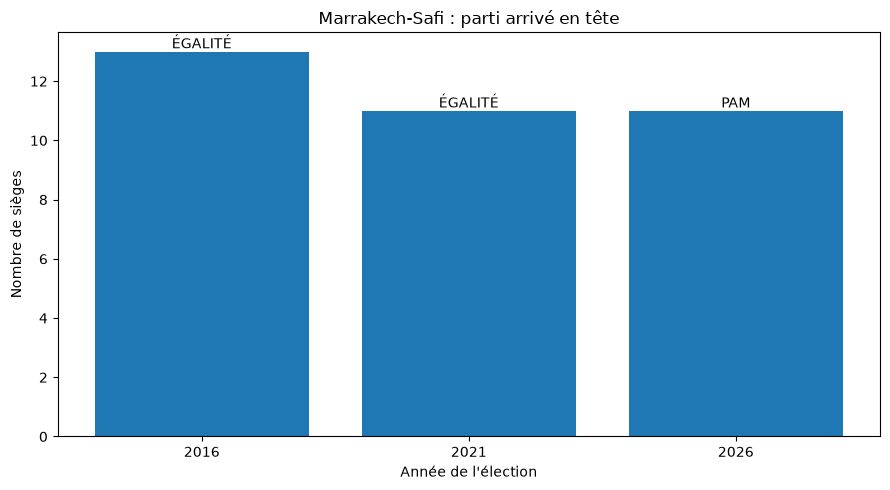

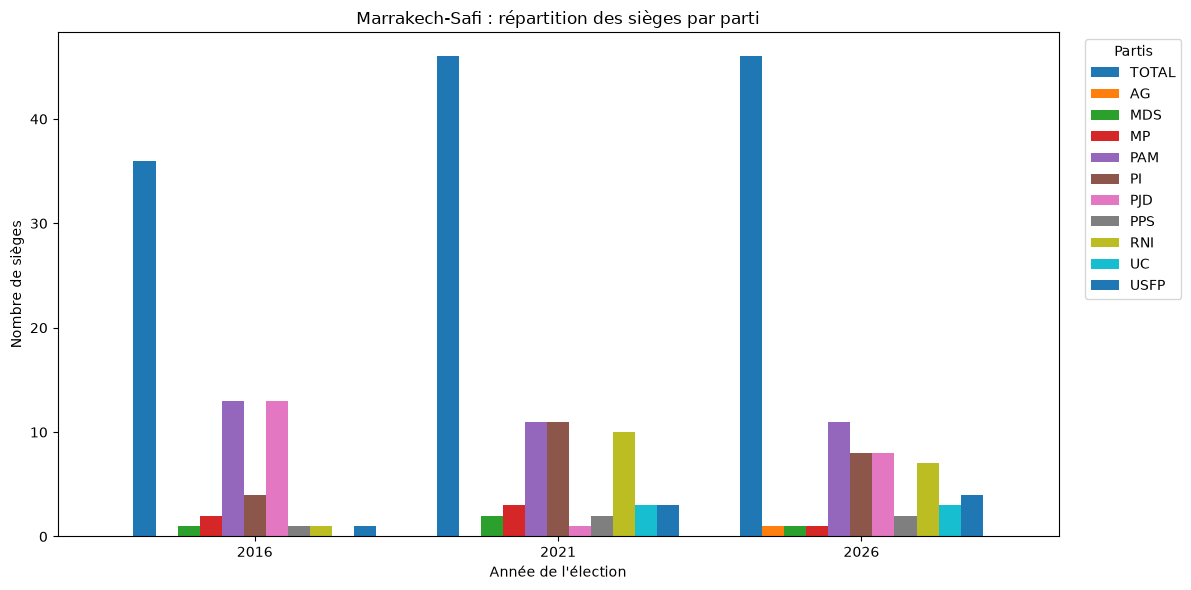

In [5]:

import matplotlib.pyplot as plt

# Filtrer Marrakech-Safi
marrakech = df[
    df["region_fr"].str.contains("Marrakech-Safi", case=False, na=False)
].copy()

if marrakech.empty:
    print("Marrakech-Safi introuvable.")
    print("Régions disponibles :", df["region_fr"].unique())
else:
    marrakech = marrakech.sort_values("year")

    # 1. Évolution des sièges du parti arrivé en tête
    plt.figure(figsize=(9, 5))
    bars = plt.bar(
        marrakech["year"].astype(str),
        marrakech["lead_seats"]
    )

    for bar, (_, row) in zip(bars, marrakech.iterrows()):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            str(row["lead_party"]),
            ha="center",
            va="bottom"
        )

    plt.title("Marrakech-Safi : parti arrivé en tête")
    plt.xlabel("Année de l'élection")
    plt.ylabel("Nombre de sièges")
    plt.tight_layout()
    plt.show()

    # 2. Comparaison des sièges par parti et par année
    colonnes_partis = [
        col for col in marrakech.columns
        if col.startswith("seats_")
    ]

    donnees = marrakech.set_index("year")[colonnes_partis].copy()
    donnees.columns = [
        col.replace("seats_", "").upper()
        for col in donnees.columns
    ]

    # Ne garder que les partis ayant obtenu au moins un siège
    donnees = donnees.loc[:, donnees.sum() > 0]

    ax = donnees.plot(
        kind="bar",
        figsize=(12, 6),
        width=0.8
    )

    ax.set_title("Marrakech-Safi : répartition des sièges par parti")
    ax.set_xlabel("Année de l'élection")
    ax.set_ylabel("Nombre de sièges")
    ax.legend(title="Partis", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


Dimensions : (21, 10)
Colonnes : ['Parti', 'Sigle', 'Voix_locales', 'Pct_locales', 'Sieges_locaux', 'Voix_regionales', 'Pct_regionales', 'Sieges_regionaux', 'Total_sieges', 'Variation_sieges']
                                     Parti Sigle  Voix_locales  Pct_locales  \
0          Parti authenticité et modernité   PAM     1043781.0        21.30   
1                      Parti de l'Istiqlal    PI      751672.0        15.34   
2  Rassemblement national des indépendants   RNI      718630.0        14.66   
3  Parti de la justice et du développement   PJD      696031.0        14.20   
4                      Mouvement populaire    MP      356172.0         7.27   

   Sieges_locaux  Voix_regionales  Pct_regionales  Sieges_regionaux  \
0           85.0        1065371.0           22.02              12.0   
1           52.0         753944.0           15.58              13.0   
2           57.0         640468.0           13.24               9.0   
3           44.0         730315.0           15.0

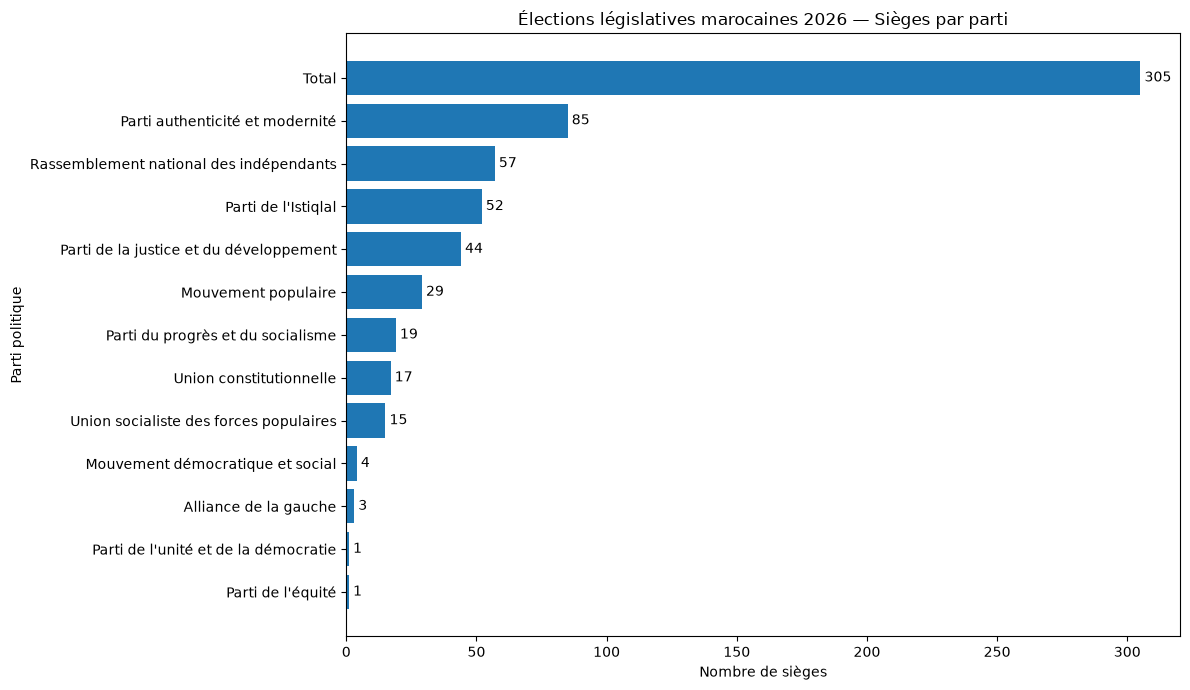

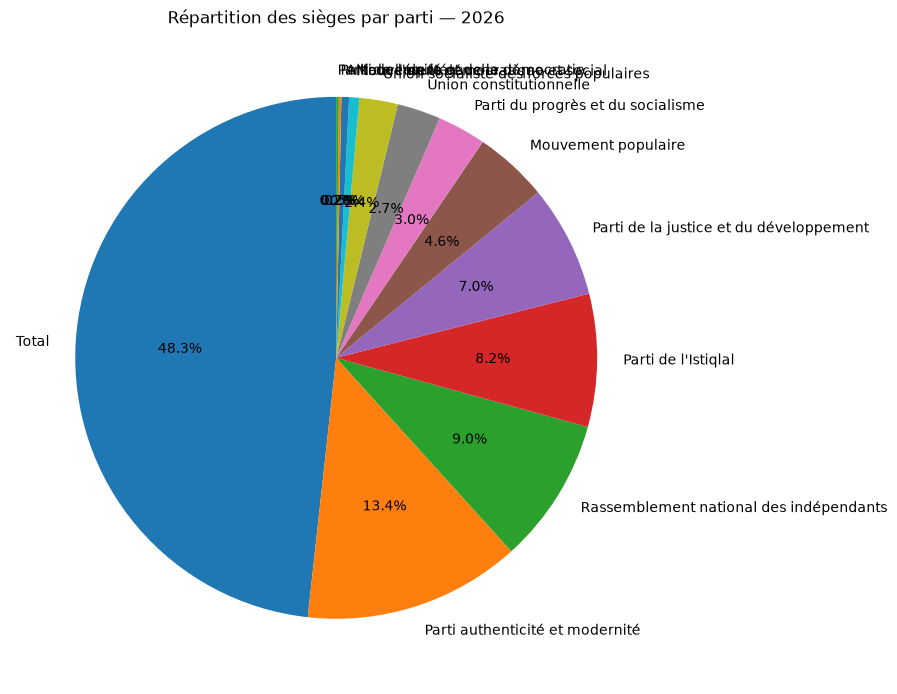

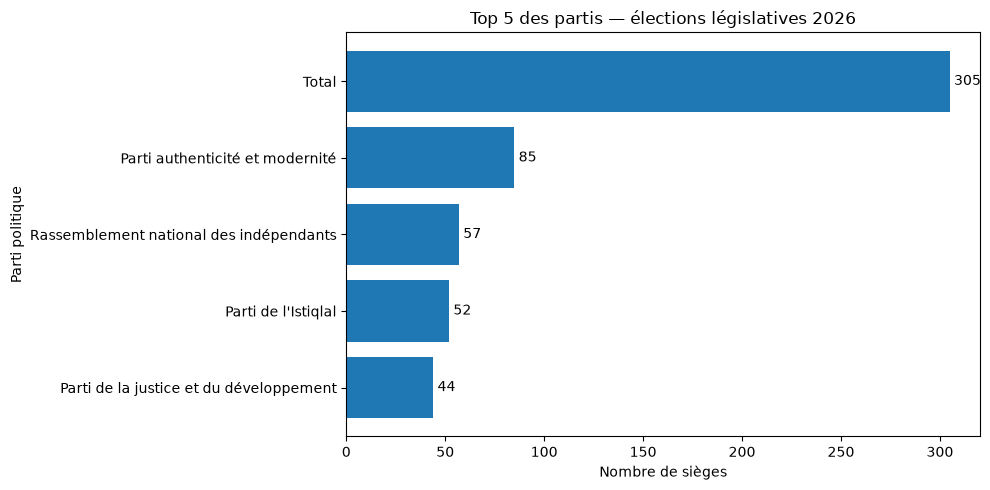


Total des sièges dans le fichier : 632.0


In [6]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Charger le fichier CSV
dossier = Path(r"C:\Users\oussama samid\AI_Projects\mini_project\dataset")
fichier = dossier / "resulta final 2026.csv"

df = pd.read_csv(fichier, encoding="utf-8-sig")

print("Dimensions :", df.shape)
print("Colonnes :", df.columns.tolist())
print(df.head())

# 2. Identifier les colonnes
# Adapter ces deux noms si ton CSV utilise d'autres intitulés.
print("\nNoms des colonnes :", df.columns.tolist())

# Suppression des espaces dans les noms
df.columns = df.columns.str.strip()

# Essayer de détecter automatiquement le parti et le nombre de sièges
col_parti = next(
    (c for c in df.columns if any(
        mot in c.lower() for mot in ["parti", "party", "formation"]
    )),
    None
)

col_sieges = next(
    (c for c in df.columns if any(
        mot in c.lower() for mot in ["siege", "siège", "seat", "nombre"]
    )),
    None
)

if col_parti is None or col_sieges is None:
    print("\nImpossible d'identifier automatiquement les colonnes.")
    print("Vérifie les noms affichés ci-dessus et adapte col_parti et col_sieges.")
else:
    # 3. Nettoyer les données
    df[col_sieges] = pd.to_numeric(df[col_sieges], errors="coerce")
    df = df.dropna(subset=[col_parti, col_sieges])
    df = df[df[col_sieges] > 0]
    df = df.sort_values(col_sieges, ascending=False)

    # 4. Graphique 1 : sièges par parti
    plt.figure(figsize=(12, 7))
    bars = plt.barh(df[col_parti], df[col_sieges])
    plt.gca().invert_yaxis()
    plt.bar_label(bars, padding=3)
    plt.title("Élections législatives marocaines 2026 — Sièges par parti")
    plt.xlabel("Nombre de sièges")
    plt.ylabel("Parti politique")
    plt.tight_layout()
    plt.show()

    # 5. Graphique 2 : pourcentage des sièges
    total_sieges = df[col_sieges].sum()
    df["pourcentage_sieges"] = df[col_sieges] / total_sieges * 100

    plt.figure(figsize=(9, 9))
    plt.pie(
        df[col_sieges],
        labels=df[col_parti],
        autopct="%1.1f%%",
        startangle=90
    )
    plt.title("Répartition des sièges par parti — 2026")
    plt.tight_layout()
    plt.show()

    # 6. Graphique 3 : top 5 des partis
    top5 = df.nlargest(5, col_sieges).sort_values(col_sieges)

    plt.figure(figsize=(10, 5))
    bars = plt.barh(top5[col_parti], top5[col_sieges])
    plt.bar_label(bars, padding=3)
    plt.title("Top 5 des partis — élections législatives 2026")
    plt.xlabel("Nombre de sièges")
    plt.ylabel("Parti politique")
    plt.tight_layout()
    plt.show()

    print("\nTotal des sièges dans le fichier :", total_sieges)
